In [15]:
# Display the Python executable path used by Jupyter
import sys

print(sys.executable)

c:\Users\ramch\AppData\Local\Programs\Python\Python311\python.exe


In [ ]:
# Import the libraries required for data generation and machine learning
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("All libraries imported successfully!")

All libraries imported successfully!


In [31]:
# Set the number of student records and random seed
NUMBER_OF_STUDENTS = 5000
RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)

print("Number of students:", NUMBER_OF_STUDENTS)
print("Random seed:", RANDOM_SEED)

Number of students: 5000
Random seed: 42


In [32]:
# Generate realistic synthetic student features using a shared engagement factor
rng = np.random.default_rng(RANDOM_SEED)

engagement = rng.normal(0, 1, NUMBER_OF_STUDENTS)

attendance = np.clip(
    72 + 13 * engagement + rng.normal(0, 10, NUMBER_OF_STUDENTS),
    0, 100
)

assignment_completion = np.clip(
    68 + 14 * engagement + rng.normal(0, 12, NUMBER_OF_STUDENTS),
    0, 100
)

previous_score = np.clip(
    62 + 12 * engagement + rng.normal(0, 13, NUMBER_OF_STUDENTS),
    0, 100
)

study_hours = np.clip(
    3.5 + 0.9 * engagement + rng.normal(0, 1.2, NUMBER_OF_STUDENTS),
    0, 8
)

participation_score = np.clip(
    60 + 14 * engagement + rng.normal(0, 15, NUMBER_OF_STUDENTS),
    0, 100
)

late_submissions = rng.binomial(
    8,
    np.clip(0.30 - 0.07 * engagement, 0.05, 0.70)
)

print("Student features generated successfully!")

Student features generated successfully!


In [33]:
# Generate future assessment scores using student performance indicators
random_noise = rng.normal(0, 8, NUMBER_OF_STUDENTS)

next_assessment_score = (
    0.30 * previous_score
    + 0.22 * attendance
    + 0.22 * assignment_completion
    + 0.12 * (study_hours / 8 * 100)
    + 0.08 * participation_score
    - 1.2 * late_submissions
    + random_noise
)

next_assessment_score = np.clip(next_assessment_score, 0, 100)

print("Future assessment scores generated successfully!")

Future assessment scores generated successfully!


In [34]:
# Create the binary target variable based on the future assessment score
at_risk = (next_assessment_score < 40).astype(int)

print("At-risk students:", np.sum(at_risk == 1))
print("Not-at-risk students:", np.sum(at_risk == 0))

At-risk students: 755
Not-at-risk students: 4245


In [35]:
# Combine all generated student features and target labels into a DataFrame
student_data = pd.DataFrame({
    "student_id": [f"STU_{i:05d}" for i in range(1, NUMBER_OF_STUDENTS + 1)],
    "attendance_percentage": attendance,
    "assignment_completion": assignment_completion,
    "previous_score": previous_score,
    "study_hours": study_hours,
    "participation_score": participation_score,
    "late_submissions": late_submissions,
    "next_assessment_score": next_assessment_score,
    "at_risk": at_risk
})

student_data.head()

,student_id,attendance_percentage,assignment_completion,previous_score,study_hours,participation_score,late_submissions,next_assessment_score,at_risk
0,STU_00001,73.381801,74.381364,77.727363,1.784405,65.433501,4,62.177183,0
1,STU_00002,55.485348,64.229704,62.017847,3.633463,33.980612,3,42.051626,0
2,STU_00003,74.789266,60.839069,80.754282,4.105768,70.613196,2,63.627996,0
3,STU_00004,88.512171,77.744328,79.008216,3.626617,69.552428,0,70.871717,0
4,STU_00005,48.983004,50.635347,43.954320,1.443087,53.574239,3,44.981374,0


In [36]:
# Inspect the structure and quality of the generated student dataset
print("Dataset shape:", student_data.shape)

print("\nColumn names:")
print(student_data.columns.tolist())

print("\nMissing values:")
print(student_data.isnull().sum())

print("\nDuplicate records:", student_data.duplicated().sum())

print("\nStatistical summary:")
display(student_data.describe())

Dataset shape: (5000, 9)

Column names:
['student_id', 'attendance_percentage', 'assignment_completion', 'previous_score', 'study_hours', 'participation_score', 'late_submissions', 'next_assessment_score', 'at_risk']

Missing values:
student_id               0
attendance_percentage    0
assignment_completion    0
previous_score           0
study_hours              0
participation_score      0
late_submissions         0
next_assessment_score    0
at_risk                  0
dtype: int64

Duplicate records: 0

Statistical summary:


,attendance_percentage,assignment_completion,previous_score,study_hours,participation_score,late_submissions,next_assessment_score,at_risk
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,71.446947,67.279927,62.298901,3.509885,59.633088,2.387600,56.235991,0.151000
std,15.576067,17.527241,17.439538,1.474857,20.327214,1.400342,15.575074,0.358085
min,11.139778,4.135418,0.000000,0.000000,0.000000,0.000000,1.654283,0.000000
25%,60.820741,54.984989,50.455980,2.500854,45.473803,1.000000,45.690851,0.000000
50%,71.811156,67.238577,62.170010,3.498270,59.932861,2.000000,56.398348,0.000000
75%,82.414291,79.684724,74.610846,4.480904,74.096658,3.000000,66.923293,0.000000
max,100.000000,100.000000,100.000000,8.000000,100.000000,7.000000,100.000000,1.000000


In [38]:
# Save the synthetic student dataset in the project's processed data folder
project_dir = Path.cwd()

if not (project_dir / "data").exists() and (project_dir.parent / "data").exists():
    project_dir = project_dir.parent

processed_dir = project_dir / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

file_path = processed_dir / "student_performance_synthetic.csv"

student_data.to_csv(file_path, index=False)

print("Dataset saved successfully!")
print("File location:", file_path)

Dataset saved successfully!
File location: c:\Users\ramch\OneDrive\Desktop\Algions ai\rist-pred\data\processed\student_performance_synthetic.csv


In [39]:
# Load the generated student dataset for exploratory data analysis
student_data = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", student_data.shape)

display(student_data.head())

Dataset loaded successfully!
Dataset shape: (5000, 9)


,student_id,attendance_percentage,assignment_completion,previous_score,study_hours,participation_score,late_submissions,next_assessment_score,at_risk
0,STU_00001,73.381801,74.381364,77.727363,1.784405,65.433501,4,62.177183,0
1,STU_00002,55.485348,64.229704,62.017847,3.633463,33.980612,3,42.051626,0
2,STU_00003,74.789266,60.839069,80.754282,4.105768,70.613196,2,63.627996,0
3,STU_00004,88.512171,77.744328,79.008216,3.626617,69.552428,0,70.871717,0
4,STU_00005,48.983004,50.635347,43.954320,1.443087,53.574239,3,44.981374,0


,Student Count,Percentage
Not At Risk (0),4245,84.9
At Risk (1),755,15.1


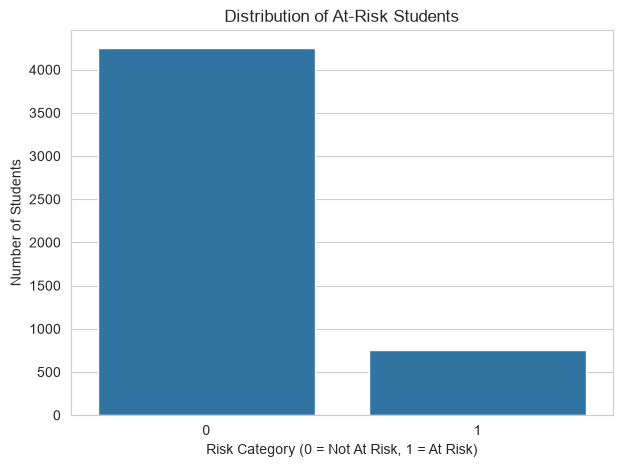

In [40]:
# Calculate the number and percentage of students in each risk category
risk_counts = student_data["at_risk"].value_counts().sort_index()

risk_percentages = student_data["at_risk"].value_counts(normalize=True).sort_index() * 100

risk_summary = pd.DataFrame({
    "Student Count": risk_counts,
    "Percentage": risk_percentages
})

risk_summary.index = ["Not At Risk (0)", "At Risk (1)"]

display(risk_summary)

# Visualize the target class distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=student_data, x="at_risk")

plt.title("Distribution of At-Risk Students")
plt.xlabel("Risk Category (0 = Not At Risk, 1 = At Risk)")
plt.ylabel("Number of Students")
plt.show()

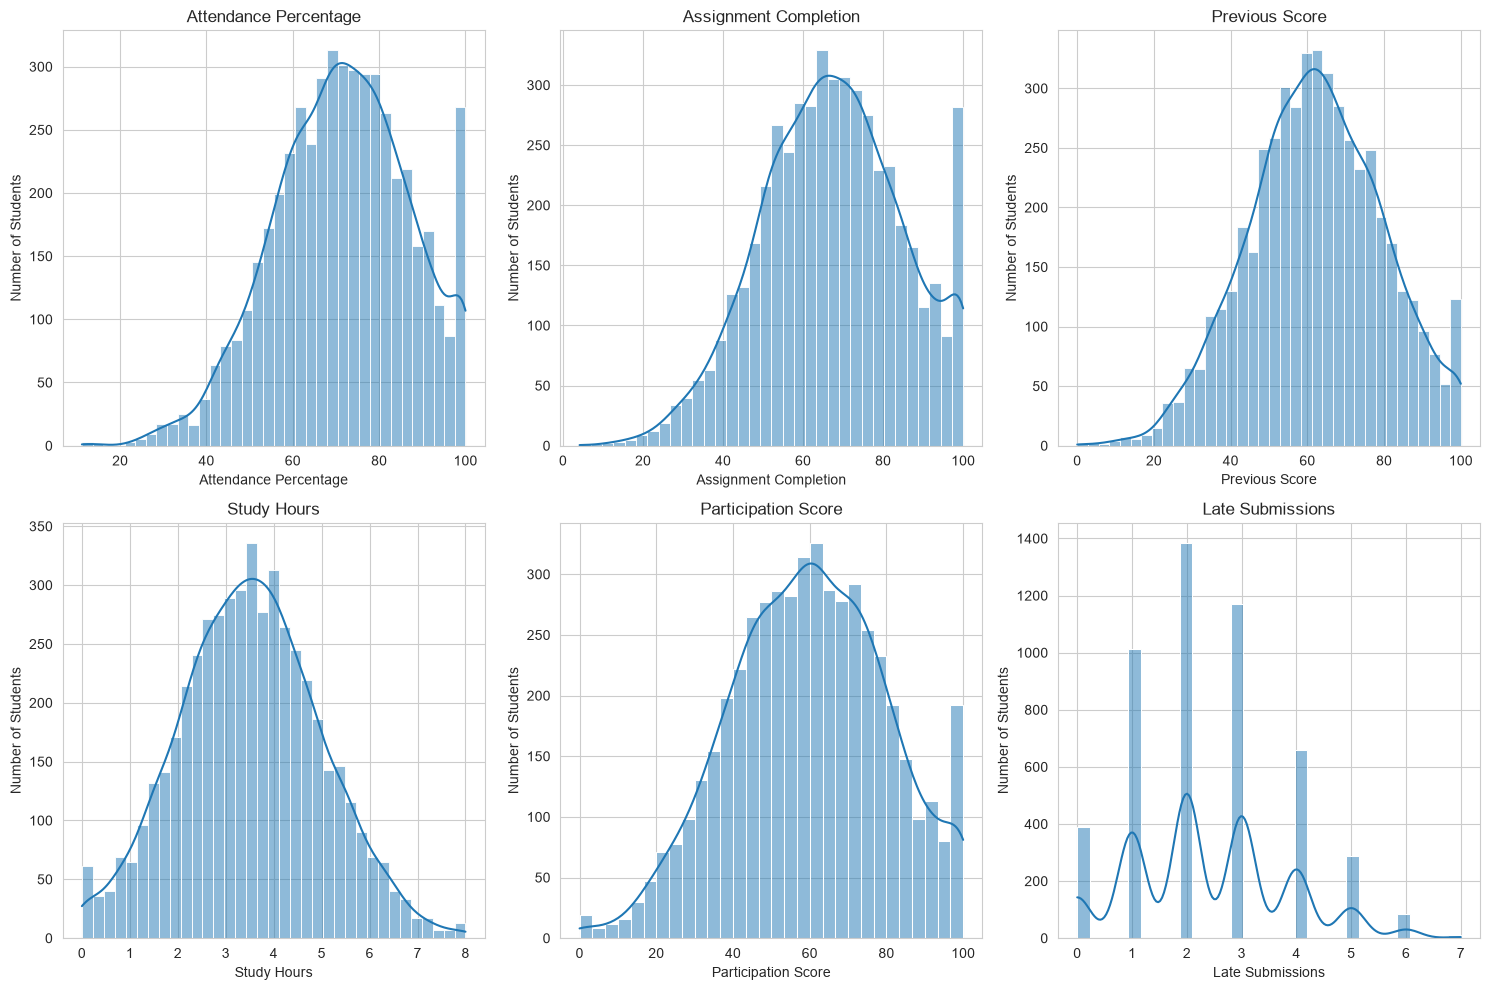

In [41]:
# Visualize the distributions of important student performance features
features = [
    "attendance_percentage",
    "assignment_completion",
    "previous_score",
    "study_hours",
    "participation_score",
    "late_submissions"
]

plt.figure(figsize=(15, 10))

for i, column in enumerate(features, 1):
    plt.subplot(2, 3, i)
    sns.histplot(data=student_data, x=column, kde=True)
    plt.title(column.replace("_", " ").title())
    plt.xlabel(column.replace("_", " ").title())
    plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

,attendance_percentage,assignment_completion,previous_score,study_hours,participation_score,late_submissions
Not At Risk,74.59,70.65,65.61,3.73,63.04,2.22
At Risk,53.77,48.31,43.66,2.26,40.46,3.35


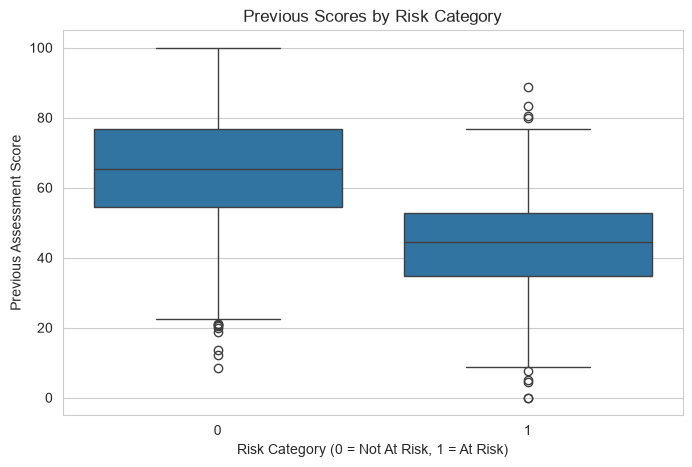

In [42]:
# Compare average student performance indicators across risk categories
comparison = student_data.groupby("at_risk")[features].mean().round(2)

comparison.index = ["Not At Risk", "At Risk"]

display(comparison)

# Visualize how previous scores differ between the two groups
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=student_data,
    x="at_risk",
    y="previous_score"
)

plt.title("Previous Scores by Risk Category")
plt.xlabel("Risk Category (0 = Not At Risk, 1 = At Risk)")
plt.ylabel("Previous Assessment Score")
plt.show()

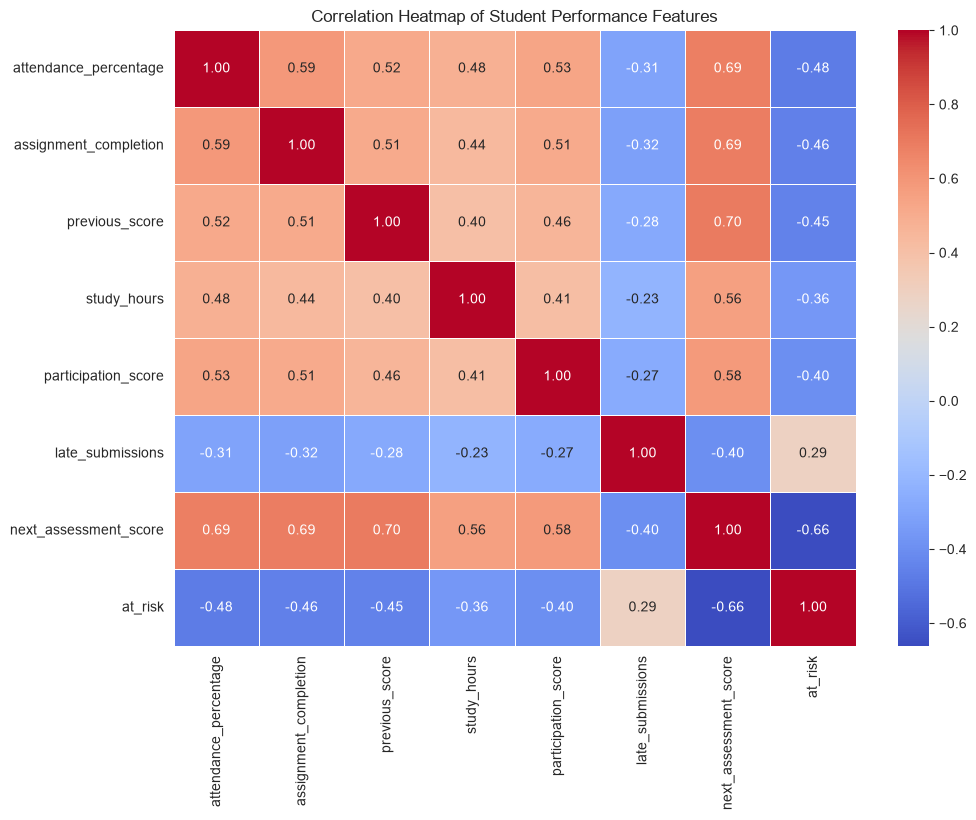

In [43]:
# Calculate and visualize correlations between numerical dataset columns
correlation_matrix = student_data.drop(columns=["student_id"]).corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Student Performance Features")
plt.show()

In [44]:
# Perform a final data quality check before preparing model features

print("DATASET INFORMATION")
student_data.info()

print("\nMISSING VALUES")
print(student_data.isnull().sum())

print("\nDUPLICATE ROWS")
print(student_data.duplicated().sum())

print("\nNUMERICAL FEATURE RANGES")
display(student_data.describe().round(2))

print("\nINVALID VALUES CHECK")
print("Attendance above 100:", (student_data["attendance_percentage"] > 100).sum())
print("Assignment completion above 100:", (student_data["assignment_completion"] > 100).sum())
print("Previous scores below 0:", (student_data["previous_score"] < 0).sum())
print("Study hours above 24:", (student_data["study_hours"] > 24).sum())

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             5000 non-null   str    
 1   attendance_percentage  5000 non-null   float64
 2   assignment_completion  5000 non-null   float64
 3   previous_score         5000 non-null   float64
 4   study_hours            5000 non-null   float64
 5   participation_score    5000 non-null   float64
 6   late_submissions       5000 non-null   int64  
 7   next_assessment_score  5000 non-null   float64
 8   at_risk                5000 non-null   int64  
dtypes: float64(6), int64(2), str(1)
memory usage: 351.7 KB

MISSING VALUES
student_id               0
attendance_percentage    0
assignment_completion    0
previous_score           0
study_hours              0
participation_score      0
late_submissions         0
next_assessment_score    0
at_risk              

,attendance_percentage,assignment_completion,previous_score,study_hours,participation_score,late_submissions,next_assessment_score,at_risk
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,71.45,67.28,62.30,3.51,59.63,2.39,56.24,0.15
std,15.58,17.53,17.44,1.47,20.33,1.40,15.58,0.36
min,11.14,4.14,0.00,0.00,0.00,0.00,1.65,0.00
25%,60.82,54.98,50.46,2.50,45.47,1.00,45.69,0.00
50%,71.81,67.24,62.17,3.50,59.93,2.00,56.40,0.00
75%,82.41,79.68,74.61,4.48,74.10,3.00,66.92,0.00
max,100.00,100.00,100.00,8.00,100.00,7.00,100.00,1.00



INVALID VALUES CHECK
Attendance above 100: 0
Assignment completion above 100: 0
Previous scores below 0: 0
Study hours above 24: 0


In [45]:
# Separate model input features from the target variable

X = student_data.drop(
    columns=["student_id", "next_assessment_score", "at_risk"]
)

y = student_data["at_risk"]

print("FEATURES (X)")
print(X.head())

print("\nTARGET (y)")
print(y.head())

print("\nNumber of input features:", X.shape[1])
print("Number of target records:", y.shape[0])

FEATURES (X)
   attendance_percentage  assignment_completion  previous_score  study_hours  \
0              73.381801              74.381364       77.727363     1.784405   
1              55.485348              64.229704       62.017847     3.633463   
2              74.789266              60.839069       80.754282     4.105768   
3              88.512171              77.744328       79.008216     3.626617   
4              48.983004              50.635347       43.954320     1.443087   

   participation_score  late_submissions  
0            65.433501                 4  
1            33.980612                 3  
2            70.613196                 2  
3            69.552428                 0  
4            53.574239                 3  

TARGET (y)
0    0
1    0
2    0
3    0
4    0
Name: at_risk, dtype: int64

Number of input features: 6
Number of target records: 5000


In [46]:
# Verify that no target leakage columns are present in the model features

print("Selected features:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

assert "next_assessment_score" not in X.columns
assert "student_id" not in X.columns
assert "at_risk" not in X.columns

print("\nFeature selection verified successfully!")

Selected features:
['attendance_percentage', 'assignment_completion', 'previous_score', 'study_hours', 'participation_score', 'late_submissions']

Target distribution:
at_risk
0    4245
1     755
Name: count, dtype: int64

Target percentages:
at_risk
0    84.9
1    15.1
Name: proportion, dtype: float64

Feature selection verified successfully!


In [47]:
# Split the features and target into training and testing datasets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (4000, 6)
Testing features: (1000, 6)

Training target distribution:
at_risk
0    3396
1     604
Name: count, dtype: int64

Testing target distribution:
at_risk
0    849
1    151
Name: count, dtype: int64


In [48]:
# Standardize numerical features using statistics learned from training data only
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data scaled:", X_train_scaled.shape)
print("Testing data scaled:", X_test_scaled.shape)
print("\nFeature scaling completed successfully!")

Training data scaled: (4000, 6)
Testing data scaled: (1000, 6)

Feature scaling completed successfully!


In [50]:
# Create and train the Logistic Regression model
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.918
Precision: 0.7634
Recall: 0.6623
F1 Score: 0.7092

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       849
           1       0.76      0.66      0.71       151

    accuracy                           0.92      1000
   macro avg       0.85      0.81      0.83      1000
weighted avg       0.91      0.92      0.92      1000



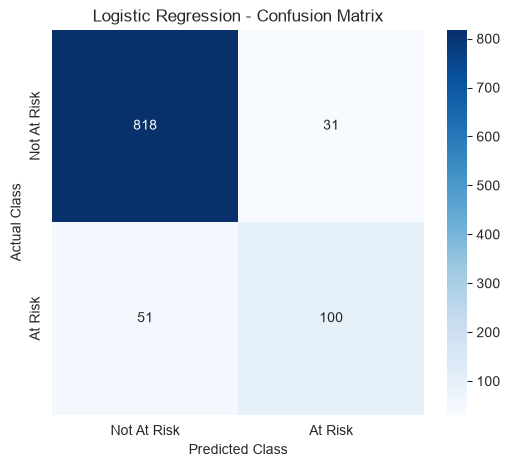

In [51]:
# Generate predictions and evaluate Logistic Regression performance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

y_pred_logistic = logistic_model.predict(X_test_scaled)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_logistic), 4))
print("Precision:", round(precision_score(y_test, y_pred_logistic, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_logistic, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_logistic, zero_division=0), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_logistic, zero_division=0))

# Display the confusion matrix
cm = confusion_matrix(y_test, y_pred_logistic)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not At Risk", "At Risk"],
    yticklabels=["Not At Risk", "At Risk"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [52]:
# Train a Random Forest classifier using the training dataset
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    class_weight="balanced"
)

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


RANDOM FOREST RESULTS
---------------------
Accuracy: 0.895
Precision: 0.6292
Recall: 0.7417
F1 Score: 0.6809

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.95      0.92      0.94       849
           1       0.63      0.74      0.68       151

    accuracy                           0.90      1000
   macro avg       0.79      0.83      0.81      1000
weighted avg       0.90      0.90      0.90      1000



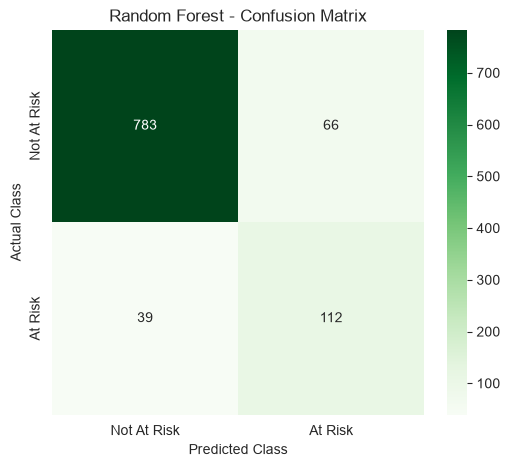

In [53]:
# Generate predictions and evaluate Random Forest performance
y_pred_rf = random_forest_model.predict(X_test)

print("RANDOM FOREST RESULTS")
print("---------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_rf, zero_division=0), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_rf, zero_division=0))

# Visualize the Random Forest confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Not At Risk", "At Risk"],
    yticklabels=["Not At Risk", "At Risk"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [54]:
# Train a Gradient Boosting classifier using the original training features
from sklearn.ensemble import GradientBoostingClassifier

gradient_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gradient_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


GRADIENT BOOSTING RESULTS
-------------------------
Accuracy: 0.91
Precision: 0.7293
Recall: 0.6424
F1 Score: 0.6831

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       849
           1       0.73      0.64      0.68       151

    accuracy                           0.91      1000
   macro avg       0.83      0.80      0.82      1000
weighted avg       0.91      0.91      0.91      1000



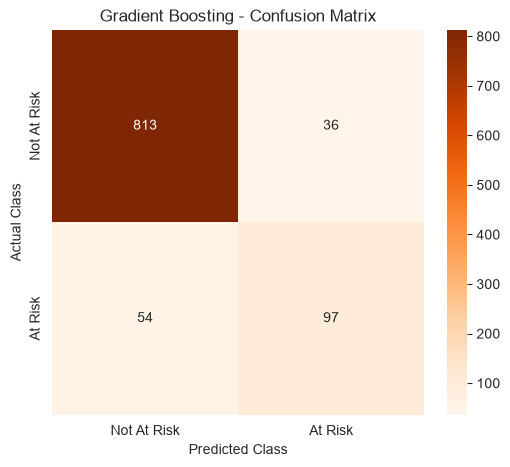

In [55]:
# Generate predictions and evaluate Gradient Boosting performance
y_pred_gb = gradient_model.predict(X_test)

print("GRADIENT BOOSTING RESULTS")
print("-------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_gb), 4))
print("Precision:", round(precision_score(y_test, y_pred_gb, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_gb, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_gb, zero_division=0), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_gb, zero_division=0))

# Visualize the Gradient Boosting confusion matrix
cm_gb = confusion_matrix(y_test, y_pred_gb)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_gb,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Not At Risk", "At Risk"],
    yticklabels=["Not At Risk", "At Risk"]
)

plt.title("Gradient Boosting - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [56]:
# Compare the evaluation metrics of all three trained models
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_logistic, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0),
        precision_score(y_test, y_pred_gb, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_logistic, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0),
        recall_score(y_test, y_pred_gb, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_logistic, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0),
        f1_score(y_test, y_pred_gb, zero_division=0)
    ]
})

display(model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.918,0.7634,0.6623,0.7092
1,Random Forest,0.895,0.6292,0.7417,0.6809
2,Gradient Boosting,0.910,0.7293,0.6424,0.6831


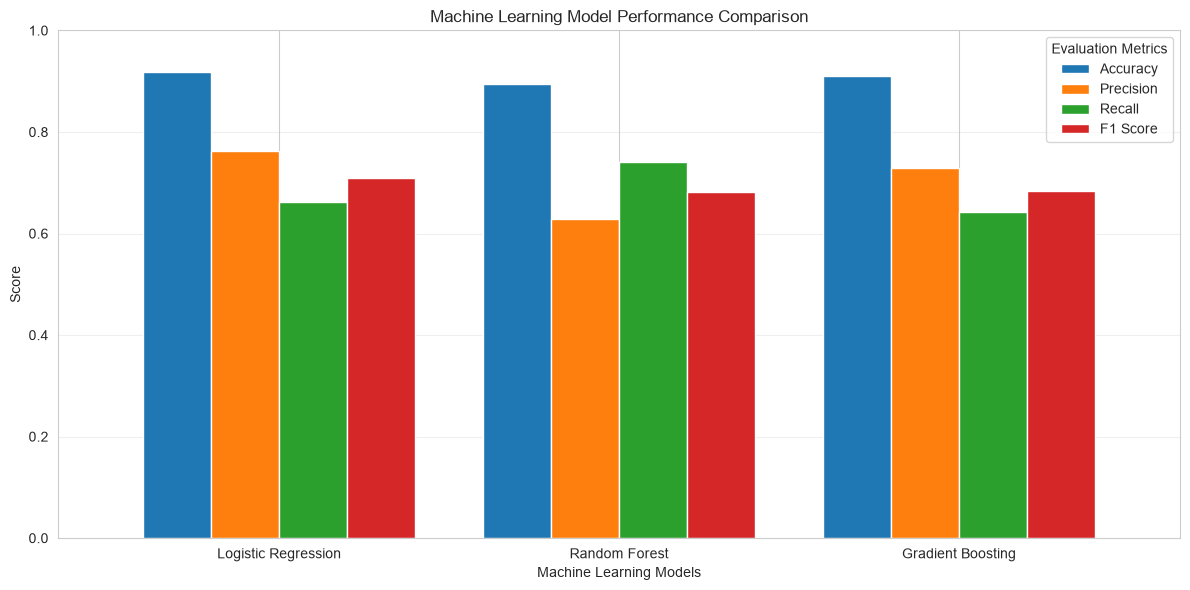

In [57]:
# Visualize the performance comparison of all three machine learning models

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

comparison_plot = model_comparison.set_index("Model")[metrics]

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Machine Learning Model Performance Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

,Feature,Importance
0,attendance_percentage,0.275087
2,previous_score,0.235589
1,assignment_completion,0.228134
4,participation_score,0.124575
3,study_hours,0.102196
5,late_submissions,0.034419


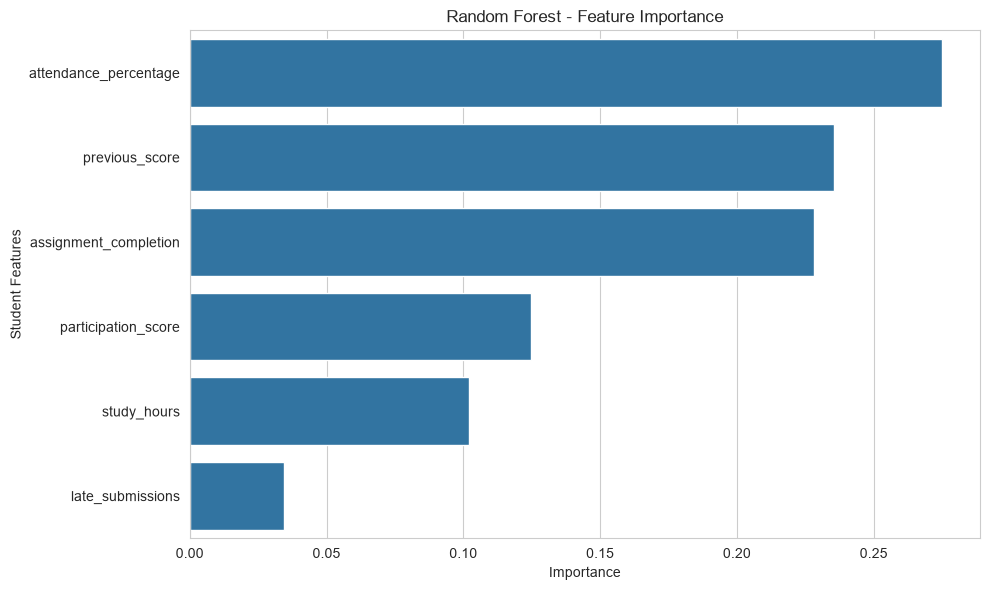

In [58]:
# Identify and visualize the feature importance learned by Random Forest

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Student Features")
plt.tight_layout()
plt.show()

In [60]:
# Split the existing training data into a smaller training set and validation set
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("New training data:", X_train_new.shape)
print("Validation data:", X_val.shape)

print("\nValidation target distribution:")
print(y_val.value_counts())

New training data: (3200, 6)
Validation data: (800, 6)

Validation target distribution:
at_risk
0    679
1    121
Name: count, dtype: int64


In [61]:
# Train a Random Forest model for classification threshold tuning
rf_tuning_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    class_weight="balanced"
)

rf_tuning_model.fit(X_train_new, y_train_new)

print("Random Forest validation model trained successfully!")

Random Forest validation model trained successfully!


In [62]:
# Calculate the predicted probability of students being at risk
y_val_probabilities = rf_tuning_model.predict_proba(X_val)[:, 1]

print("First 10 predicted probabilities:")
print(np.round(y_val_probabilities[:10], 3))

First 10 predicted probabilities:
[0.    0.675 0.001 0.061 0.212 0.717 0.004 0.037 0.498 0.791]


In [63]:
# Compare precision, recall, and F1 score at different classification thresholds
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

threshold_results = []

for threshold in thresholds:

    predictions = (y_val_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1 Score": f1_score(y_val, predictions, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1 Score
0,0.30,0.5251,0.7769,0.6267
1,0.35,0.5528,0.7355,0.6312
2,0.40,0.5658,0.7107,0.6300
3,0.45,0.5643,0.6529,0.6054
4,0.50,0.5950,0.5950,0.5950
5,0.55,0.6239,0.5620,0.5913
6,0.60,0.6465,0.5289,0.5818


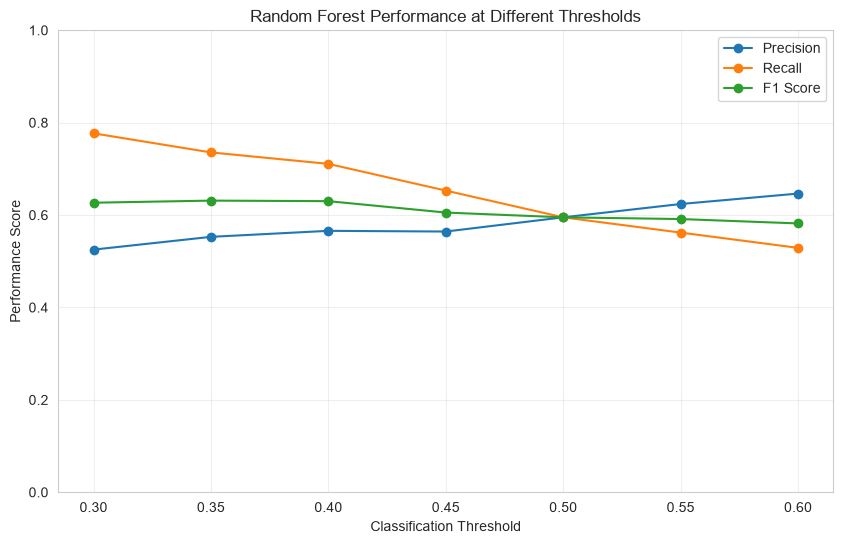

In [64]:
# Visualize how different classification thresholds affect model performance
plt.figure(figsize=(10, 6))

for metric in ["Precision", "Recall", "F1 Score"]:
    plt.plot(
        threshold_df["Threshold"],
        threshold_df[metric],
        marker="o",
        label=metric
    )

plt.title("Random Forest Performance at Different Thresholds")
plt.xlabel("Classification Threshold")
plt.ylabel("Performance Score")
plt.xticks(thresholds)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [66]:
# Recreate and train the final Random Forest model
from sklearn.ensemble import RandomForestClassifier

final_rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    class_weight="balanced"
)

final_rf_model.fit(X_train, y_train)

print("Final Random Forest model trained successfully!")

Final Random Forest model trained successfully!


,Feature,Importance
0,attendance_percentage,0.2751
2,previous_score,0.2356
1,assignment_completion,0.2281
4,participation_score,0.1246
3,study_hours,0.1022
5,late_submissions,0.0344


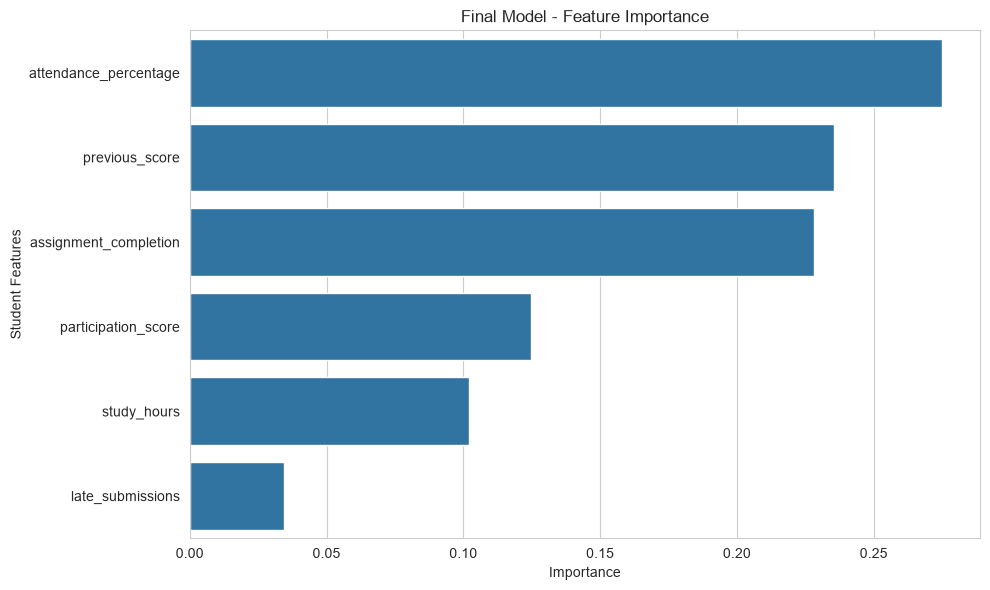

In [67]:
# Calculate and visualize feature importance from the final Random Forest model

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": final_rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.round(4))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Final Model - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Student Features")
plt.tight_layout()
plt.show()

In [69]:
# Restore the selected classification threshold from our validation analysis
best_threshold = 0.35

print("Selected threshold:", best_threshold)

Selected threshold: 0.35


In [70]:
# Save the final Random Forest model and its prediction configuration
import joblib
from pathlib import Path

project_dir = Path.cwd()

if not (project_dir / "models").exists() and (project_dir.parent / "models").exists():
    project_dir = project_dir.parent

models_dir = project_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

model_bundle = {
    "model": final_rf_model,
    "threshold": best_threshold,
    "features": X.columns.tolist(),
    "target_definition": "At risk if next assessment score is below 40"
}

model_path = models_dir / "student_risk_model.joblib"

joblib.dump(model_bundle, model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: c:\Users\ramch\OneDrive\Desktop\Algions ai\rist-pred\models\student_risk_model.joblib


In [3]:
# Define the path of our previously saved Random Forest model
from pathlib import Path

project_dir = Path.cwd()
if not (project_dir / "models").exists() and (project_dir.parent / "models").exists():
    project_dir = project_dir.parent

model_path = project_dir / "models" / "student_risk_model.joblib"

print("Model file exists:", model_path.exists())


Model file exists: True


In [4]:
# Load the saved model and verify its configuration
import joblib

loaded_bundle = joblib.load(model_path)

loaded_model = loaded_bundle["model"]
loaded_threshold = loaded_bundle["threshold"]
loaded_features = loaded_bundle["features"]

print("Model loaded successfully!")
print("Threshold:", loaded_threshold)
print("Features:", loaded_features)

Model loaded successfully!
Threshold: 0.35
Features: ['attendance_percentage', 'assignment_completion', 'previous_score', 'study_hours', 'participation_score', 'late_submissions']


In [ ]:
# Import the libraries required for making student predictions
import pandas as pd
import numpy as np
import joblib

print("Required libraries imported successfully!")

In [7]:
# Predict the academic risk of a new student using our saved model

sample_student = pd.DataFrame([{
    "attendance_percentage": 55,
    "assignment_completion": 45,
    "previous_score": 38,
    "study_hours": 2,
    "participation_score": 40,
    "late_submissions": 5
}])

# Arrange the input features in the exact order expected by the model
sample_student = sample_student[loaded_features]

# Calculate the probability and predicted risk category
risk_probability = loaded_model.predict_proba(sample_student)[0][1]

risk_prediction = int(risk_probability >= loaded_threshold)

print("STUDENT RISK PREDICTION")
print("-----------------------")
print("Risk Probability:", round(risk_probability * 100, 2), "%")
print("Prediction:", "At Risk" if risk_prediction == 1 else "Not At Risk")
print("Threshold:", loaded_threshold)

NameError: name 'pd' is not defined